# RNN Learner Notebook 4: From RNN to LSTM — Learning Long-Term Dependencies

**Text sequence modelling and sentiment classification**

## Overview
The previous notebooks covered RNN fundamentals, unfolding/training through time, and time-series prediction. This notebook moves to **text data** and introduces Long Short-Term Memory (LSTM) networks.

We use two datasets:
1. **A small, self-created text corpus** for next-word prediction. This helps us inspect tokens and training sequences.
2. **The public IMDb movie-review dataset** for positive/negative sentiment classification.

The first dataset teaches the workflow; the second demonstrates a real text classification task. The tiny corpus is only for demonstration and will not produce a general-purpose language model.

## Learning objectives
By the end, you should be able to:
- Explain why basic RNNs may struggle with long-term dependencies and describe vanishing gradients conceptually.
- Explain LSTM cell state, hidden state, forget gate, input gate, and output gate.
- Interpret the main LSTM equations.
- Prepare text using tokenization, integer sequences, and padding.
- Build an LSTM next-word predictor and an IMDb sentiment classifier.
- Evaluate predictions and discuss limitations.

## Instructions
1. Run cells from top to bottom.
2. Read each explanation before executing the following code.
3. Observe outputs and complete the activities.
4. GPU is optional; select **Runtime → Change runtime type → T4 GPU** if available.
5. IMDb data is downloaded at runtime and requires an internet connection.

## 1. Recap: How does a basic RNN process text?

Text is a sequence of tokens. For example: `the student reads a book`. A model converts tokens into numerical representations and processes them in order. At time step \(t\), a basic RNN combines the current input and previous hidden state:

$$
h_t = f(W_x x_t + W_h h_{t-1} + b)
$$

Here, \(x_t\) is the current input, \(h_{t-1}\) is the previous hidden state, \(W_x\) and \(W_h\) are learned weights, \(b\) is a bias, and \(f\) is an activation function.

The hidden state acts as a summary of information processed so far. However, when useful information is many time steps away, a basic RNN may struggle to learn the relationship.

## 2. Why can a basic RNN struggle with long-term dependencies?

During Backpropagation Through Time (BPTT), learning signals travel backward through the sequence. Repeated multiplication by derivatives can make gradients very small, causing the **vanishing-gradient problem**. Gradients can also become too large, causing the **exploding-gradient problem**.

LSTM was designed to improve learning of longer dependencies. It introduces a cell state and gates that regulate information flow. LSTM can help, but it does not guarantee perfect memory or better results on every dataset.

## 3. LSTM architecture and equations

An LSTM maintains two states:
- **Cell state (\(C_t\)):** a pathway for carrying information through the sequence.
- **Hidden state (\(h_t\)):** passed to the next time step and often used to produce output.

The forget gate controls retention of previous cell-state information. The input gate controls how much candidate information is added. The output gate controls how much updated cell-state information contributes to the hidden state.

Let \(x_t\) be the current input, \(h_{t-1}\) the previous hidden state, and \(C_{t-1}\) the previous cell state. The notation \([h_{t-1},x_t]\) means concatenation; \(\odot\) means element-wise multiplication.

**Forget gate**
$$f_t = \sigma(W_f[h_{t-1},x_t] + b_f)$$

**Input gate**
$$i_t = \sigma(W_i[h_{t-1},x_t] + b_i)$$

**Candidate cell content**
$$
\widetilde{C}_t = \tanh(W_C[h_{t-1},x_t]+b_C)
$$

**Cell-state update**
$$C_t = f_t \odot C_{t-1} + i_t \\odot \widetilde{C}_t$$

**Output gate and hidden state**
$$o_t = \sigma(W_o[h_{t-1},x_t] + b_o)$$
$$h_t = o_t \odot \tanh(C_t)$$

Sigmoid outputs values between zero and one; tanh outputs values between minus one and one.

### Worked numerical example

Suppose a component of the previous cell state is 0.8, the forget-gate value is 0.5, the input-gate value is 0.4, and the candidate cell value is 0.6.

$$C_t = f_t C_{t-1} + i_t\widetilde{C}_t$$
$$C_t = (0.5 \times 0.8) + (0.4 \times 0.6)$$
$$C_t = 0.4 + 0.24 = 0.64$$

The updated cell-state value is **0.64**. A real LSTM performs these calculations over vectors with learned gate values.

### Activity 1 — Check your understanding
1. What is the purpose of the cell state?
2. What does the forget gate control?
3. How is the cell state different from the hidden state?
4. What does a forget-gate value close to 1 suggest?
5. Why is LSTM not guaranteed to outperform a basic RNN on every task?

**Self-check:** The cell state carries information through the sequence; the forget gate regulates retention; a value close to 1 means most of the corresponding previous cell-state component is retained; model performance depends on data, architecture, and training.

## 4. Dataset 1 — A small text corpus for next-word prediction

### Task
We will create short sentences and train an LSTM to predict the next word from preceding words. For example, the prompt `deep learning` might lead to `uses` if that pattern occurs in the training corpus.

**Limitation:** The corpus is tiny and repetitive. The model learns patterns in these examples, not language in general.

### Step 1 — Import libraries and create the corpus

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

sentences = [
    "deep learning uses neural networks",
    "deep learning learns useful patterns",
    "neural networks learn from data",
    "recurrent networks process sequences",
    "lstm networks learn sequence patterns",
    "students learn deep learning",
    "students build neural networks",
    "text data contains word sequences",
    "lstm models process text sequences",
    "neural networks learn patterns from data",
    "deep learning models learn from examples",
    "students study recurrent neural networks",
    "recurrent neural networks process text",
    "lstm networks process long sequences",
    "learning models use training data",
    "text models predict the next word",
    "neural networks predict useful outputs",
    "students use python to build models",
    "python models learn from examples",
    "deep learning models process text data"
]
print("Number of sentences:", len(sentences))
for s in sentences[:5]:
    print("-", s)

Number of sentences: 20
- deep learning uses neural networks
- deep learning learns useful patterns
- neural networks learn from data
- recurrent networks process sequences
- lstm networks learn sequence patterns


### Step 2 — Tokenize the text

Tokenization assigns an integer ID to each word. These IDs are identifiers; they do not imply that one word is more important than another.

In [ ]:
tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts(sentences)
word_index = tokenizer.word_index
vocab_size = len(word_index) + 1  # index 0 is reserved for padding
sequences = tokenizer.texts_to_sequences(sentences)

print("Vocabulary size (including padding index):", vocab_size)
print("First 20 word-index entries:", list(word_index.items())[:20])
print("Example sentence:", sentences[0])
print("Token sequence:", sequences[0])

Vocabulary size (including padding index): 35
First 20 word-index entries: [('<OOV>', 1), ('networks', 2), ('neural', 3), ('models', 4), ('learning', 5), ('learn', 6), ('deep', 7), ('data', 8), ('process', 9), ('text', 10), ('from', 11), ('sequences', 12), ('students', 13), ('patterns', 14), ('recurrent', 15), ('lstm', 16), ('useful', 17), ('build', 18), ('word', 19), ('examples', 20)]
Example sentence: deep learning uses neural networks
Token sequence: [7, 5, 24, 3, 2]


### Step 3 — Create input sequences and next-word targets

Each sentence creates progressively longer prefixes. For “deep learning uses neural networks”, examples include `deep → learning`, `deep learning → uses`, and `deep learning uses → neural`. Padding makes input lengths consistent.

In [ ]:
input_sequences = []
for sequence in sequences:
    for end_index in range(1, len(sequence)):
        input_sequences.append(sequence[:end_index + 1])

max_sequence_length = max(len(seq) for seq in input_sequences)
padded = pad_sequences(input_sequences, maxlen=max_sequence_length, padding="pre")
X_next = padded[:, :-1]
y_next = padded[:, -1]

print("Training examples:", len(X_next))
print("Input shape:", X_next.shape, "Target shape:", y_next.shape)
print("One padded example:", padded[0])
print("Input tokens:", X_next[0], "Target token:", y_next[0])

Training examples: 82
Input shape: (82, 5) Target shape: (82,)
One padded example: [0 0 0 0 7 5]
Input tokens: [0 0 0 0 7] Target token: 5


### Step 4 — Build and train an LSTM

The embedding layer maps token IDs to trainable dense vectors. The LSTM processes the sequence, and the final Dense layer produces a score for each vocabulary item. Softmax converts scores into probabilities. Sparse categorical cross-entropy is appropriate because the target is one integer token ID.

In [ ]:
next_word_model = Sequential([
    tf.keras.layers.Input(shape=(X_next.shape[1],)),
    Embedding(input_dim=vocab_size, output_dim=32, mask_zero=True),
    LSTM(64),
    Dense(vocab_size, activation="softmax")
])
next_word_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
next_word_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 5, 32)          │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 35)             │         2,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,227 (110.26 KB)

 Trainable params: 28,227 (110.26 KB)

 Non-trainable params: 0 (0.00 B)

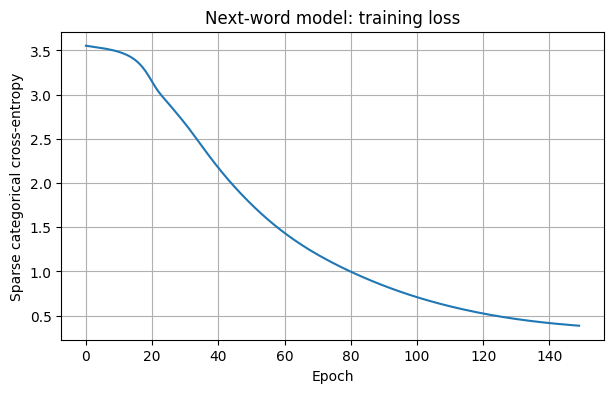

Final training loss: 0.3858
Final training accuracy: 0.8537


In [ ]:
history_next = next_word_model.fit(X_next, y_next, epochs=150, verbose=0)

plt.figure(figsize=(7, 4))
plt.plot(history_next.history["loss"])
plt.title("Next-word model: training loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy")
plt.grid(True)
plt.show()

print("Final training loss:", round(history_next.history["loss"][-1], 4))
print("Final training accuracy:", round(history_next.history["accuracy"][-1], 4))

### Step 5 — Predict the next word

The function converts a prompt to tokens, pads it to the required length, and selects the highest-probability next token. Because the corpus is small, predictions may repeat training patterns and are not evidence of broad language understanding.

In [ ]:
def predict_next_word(seed_text):
    token_list = tokenizer.texts_to_sequences([seed_text])[0]
    if not token_list:
        print("The prompt contains no known words.")
        return None
    token_list = pad_sequences([token_list], maxlen=X_next.shape[1],
                               padding="pre", truncating="pre")
    probabilities = next_word_model.predict(token_list, verbose=0)[0]
    predicted_id = int(np.argmax(probabilities))
    predicted_word = next(
        (word for word, index in tokenizer.word_index.items()
         if index == predicted_id), None
    )
    print(f"Prompt: {seed_text!r}")
    print(f"Predicted next word: {predicted_word!r}")
    print(f"Probability for this word: {probabilities[predicted_id]:.3f}")
    return predicted_word

predict_next_word("deep learning")
predict_next_word("neural networks")
predict_next_word("students learn")

Prompt: 'deep learning'
Predicted next word: 'models'
Probability for this word: 0.494
Prompt: 'neural networks'
Predicted next word: 'learn'
Probability for this word: 0.652
Prompt: 'students learn'
Predicted next word: 'deep'
Probability for this word: 0.925


'deep'

### Activity 2 — Experiment with next-word prediction

Try `text models`, `recurrent networks`, `students build`, `deep learning models`, and `python models`.

Answer:
1. Does the prediction fit a sentence in the training corpus?
2. How do repeated patterns influence predictions?
3. What happens if you enter an unknown word?
4. Why can training accuracy be misleading?
5. How might a larger, more varied corpus change the result?

**Extension:** Add three sentences, then rerun the tokenizer, sequence creation, model creation, and training cells. Changing the corpus requires retraining.

## 5. Dataset 2 — IMDb movie reviews for sentiment classification

### Dataset source and task
The IMDb Large Movie Review Dataset contains movie reviews labelled positive or negative. Keras provides a preprocessed version through `tf.keras.datasets.imdb`.

- [Keras IMDb dataset documentation](https://keras.io/api/datasets/imdb/)
- [Original Stanford dataset page](https://ai.stanford.edu/~amaas/data/sentiment/)

**Task:** Predict whether a review is positive (`1`) or negative (`0`). Reviews are represented as sequences of integer word IDs, so this version lets us focus on sequence modelling rather than raw-text cleaning.

### Step 1 — Load the dataset

The first run downloads the dataset and requires an internet connection. We restrict the vocabulary to the 10,000 most frequent word indices and keep the train/test split supplied by Keras.

In [ ]:
from tensorflow.keras.datasets import imdb

VOCAB_SIZE = 10000
MAX_REVIEW_LENGTH = 200

(X_train_imdb, y_train_imdb), (X_test_imdb, y_test_imdb) = imdb.load_data(
    num_words=VOCAB_SIZE
)
print("Training reviews:", len(X_train_imdb))
print("Testing reviews:", len(X_test_imdb))
print("First review (first 25 token IDs):", X_train_imdb[0][:25])
print("First review label:", y_train_imdb[0])
print("First review length:", len(X_train_imdb[0]))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000
Testing reviews: 25000
First review (first 25 token IDs): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50]
First review label: 1
First review length: 218


### Step 2 — Pad reviews to a consistent length

Reviews have different lengths. We pad shorter sequences and truncate longer ones to 200 tokens. Pre-padding and pre-truncation keep the most recent tokens at the end of each sequence. Other choices are possible and should be tested rather than assumed to be best.

In [ ]:
X_train_pad = pad_sequences(X_train_imdb, maxlen=MAX_REVIEW_LENGTH,
                            padding="pre", truncating="pre")
X_test_pad = pad_sequences(X_test_imdb, maxlen=MAX_REVIEW_LENGTH,
                           padding="pre", truncating="pre")
print("Padded training shape:", X_train_pad.shape)
print("Padded test shape:", X_test_pad.shape)
print("Example padded review:", X_train_pad[0][:30])

Padded training shape: (25000, 200)
Padded test shape: (25000, 200)
Example padded review: [   5   25  100   43  838  112   50  670    2    9   35  480  284    5
  150    4  172  112  167    2  336  385   39    4  172 4536 1111   17
  546   38]


### Step 3 — Inspect the labels

In [ ]:
labels, counts = np.unique(y_train_imdb, return_counts=True)
for label, count in zip(labels, counts):
    print(f"Label {label}: {count} reviews")
print("First 10 labels:", y_train_imdb[:10])

Label 0: 12500 reviews
Label 1: 12500 reviews
First 10 labels: [1 0 0 1 0 0 1 0 1 0]


### Step 4 — Build the LSTM classifier

The embedding layer converts token IDs into trainable vectors. The LSTM processes the ordered sequence. The sigmoid output estimates the probability that the review is positive. Binary cross-entropy is used for this two-class task.

In [ ]:
sentiment_model = Sequential([
    tf.keras.layers.Input(shape=(MAX_REVIEW_LENGTH,)),
    Embedding(input_dim=VOCAB_SIZE, output_dim=64, mask_zero=True),
    LSTM(64, dropout=0.2),
    Dense(1, activation="sigmoid")
])
sentiment_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
sentiment_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

### Step 5 — Train the model

A validation split is taken from the training data. The test set remains untouched until final evaluation. If training is slow, use a GPU runtime or reduce the number of epochs.

In [ ]:
EPOCHS = 3
BATCH_SIZE = 128

history_sentiment = sentiment_model.fit(
    X_train_pad, y_train_imdb,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    verbose=1
)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 73s 449ms/step - accuracy: 0.7576 - loss: 0.4790 - val_accuracy: 0.8680 - val_loss: 0.3229
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 86s 470ms/step - accuracy: 0.9032 - loss: 0.2477 - val_accuracy: 0.8712 - val_loss: 0.3133
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 74s 474ms/step - accuracy: 0.9170 - loss: 0.2165 - val_accuracy: 0.8754 - val_loss: 0.3156


### Step 6 — Plot training and validation performance

Training accuracy is measured on the training portion; validation accuracy is measured on held-out training examples. A widening gap between training and validation performance can indicate overfitting.

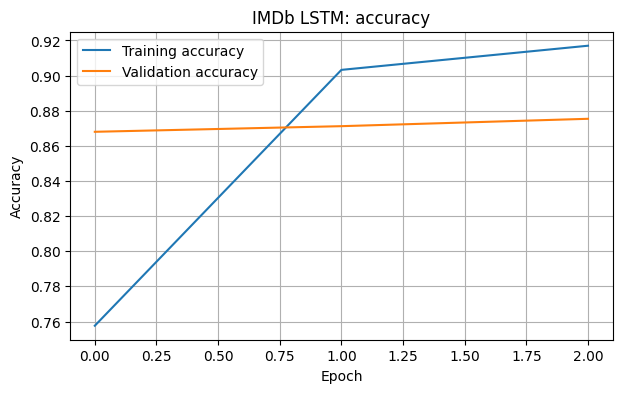

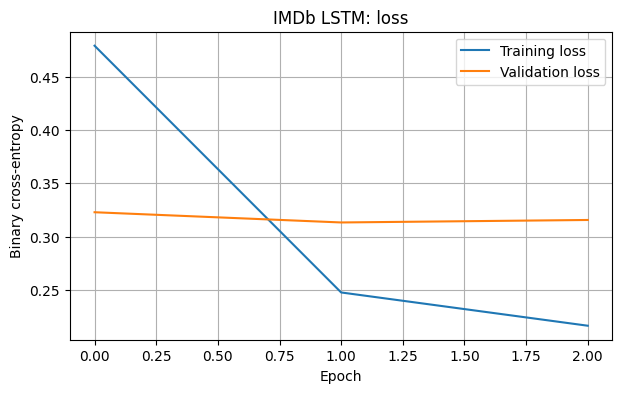

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history_sentiment.history["accuracy"], label="Training accuracy")
plt.plot(history_sentiment.history["val_accuracy"], label="Validation accuracy")
plt.title("IMDb LSTM: accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history_sentiment.history["loss"], label="Training loss")
plt.plot(history_sentiment.history["val_loss"], label="Validation loss")
plt.title("IMDb LSTM: loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy")
plt.legend(); plt.grid(True); plt.show()

### Step 7 — Evaluate on the test set

Accuracy is the proportion of correct predictions. Precision measures how many predicted-positive reviews are truly positive. Recall measures how many actual-positive reviews are identified. F1-score combines precision and recall. The confusion matrix shows correct and incorrect predictions by class.

196/196 ━━━━━━━━━━━━━━━━━━━━ 28s 141ms/step
Test accuracy : 0.8680
Test precision: 0.8591
Test recall   : 0.8802
Test F1-score : 0.8696
              precision    recall  f1-score   support

    Negative       0.88      0.86      0.87     12500
    Positive       0.86      0.88      0.87     12500

    accuracy                           0.87     25000
   macro avg       0.87      0.87      0.87     25000
weighted avg       0.87      0.87      0.87     25000



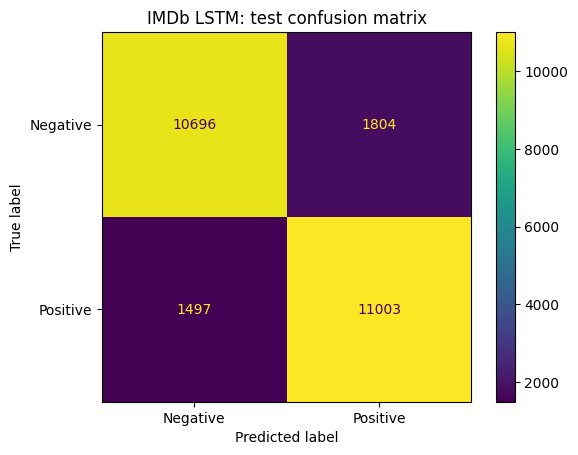

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

test_probs = sentiment_model.predict(X_test_pad, batch_size=BATCH_SIZE,
                                     verbose=1).ravel()
y_pred = (test_probs >= 0.5).astype(int)

print(f"Test accuracy : {accuracy_score(y_test_imdb, y_pred):.4f}")
print(f"Test precision: {precision_score(y_test_imdb, y_pred, zero_division=0):.4f}")
print(f"Test recall   : {recall_score(y_test_imdb, y_pred, zero_division=0):.4f}")
print(f"Test F1-score : {f1_score(y_test_imdb, y_pred, zero_division=0):.4f}")
print(classification_report(y_test_imdb, y_pred,
                            target_names=["Negative", "Positive"],
                            zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test_imdb, y_pred),
    display_labels=["Negative", "Positive"]
).plot()
plt.title("IMDb LSTM: test confusion matrix")
plt.show()

### Step 8 — Decode a review and inspect its prediction

The Keras IMDb dataset is preprocessed. Decoding provides a readable approximation, including special markers, rather than the original punctuation and formatting.

In [ ]:
word_to_id = imdb.get_word_index()
id_to_word = {index + 3: word for word, index in word_to_id.items()}
id_to_word.update({0: "<PAD>", 1: "<START>", 2: "<UNK>", 3: "<UNUSED>"})

def decode_review(token_ids):
    return " ".join(id_to_word.get(int(token), "<UNK>")
                    for token in token_ids if int(token) != 0)

sample_index = 0
print("Decoded review excerpt:")
print(decode_review(X_train_imdb[sample_index])[:1000])
print("Actual label:", "Positive" if y_train_imdb[sample_index] else "Negative")

Decoded review excerpt:
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for <UNK> and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also <UNK> to the two little boy's that played the <UNK> of norman and paul they were just brilliant children are often left out of the <UNK> list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and s

In [ ]:
prob = float(sentiment_model.predict(
    X_train_pad[sample_index:sample_index + 1], verbose=0
)[0, 0])
print("Predicted sentiment:", "Positive" if prob >= 0.5 else "Negative")
print(f"Estimated positive probability: {prob:.3f}")

Predicted sentiment: Positive
Estimated positive probability: 0.984


### Activity 3 — Interpret sentiment predictions

1. Compare the predicted sentiment with the actual label.
2. Inspect examples where the model is wrong.
3. How can a review contain both positive and negative words?
4. How might negation, sarcasm, or review length affect the prediction?
5. Why should the test set not be used repeatedly to tune model settings?

Optional: Inspect predictions near 0.5. These are less decisive according to the model output, but probability is not a guarantee of correctness or calibrated confidence.

## 6. Compare the two practicals

| Feature | Self-created corpus | IMDb reviews |
|---|---|---|
| Task | Next-word prediction | Sentiment classification |
| Data | Short demonstration sentences | Public movie reviews |
| Target | Next token ID | Positive/negative label |
| Output | Softmax over vocabulary | Sigmoid probability |
| Loss | Sparse categorical cross-entropy | Binary cross-entropy |
| Main lesson | Constructing text input/target sequences | Using an LSTM representation for classification |
| Limitation | Tiny corpus; weak generalization | Longer training; preprocessed sequences |

The two tasks both use ordered text, but their prediction goals and output layers differ.

## 7. Basic RNN versus LSTM

| Aspect | Basic RNN | LSTM |
|---|---|---|
| State | Hidden state | Hidden state and cell state |
| Information control | Recurrent update | Recurrent update with gates |
| Long dependencies | Can be difficult to learn | Designed to help preserve useful information |
| Complexity | Simpler in typical implementations | More complex, usually more parameters |
| Use | Baseline and simpler sequence tasks | Text and other tasks where longer context may help |

An LSTM is not automatically best for every task. Model choice should be guided by the data, task, computing resources, and evaluation results.

## 8. Final student exercises

**Exercise 1 — Tokenization:** Add three sentences to Dataset 1. Rerun tokenization, sequence creation, model creation, and training. Record how vocabulary size changes.

**Exercise 2 — Model capacity:** Change the next-word LSTM from 64 units to 32. Compare training loss and sample predictions.

**Exercise 3 — Review length:** Change `MAX_REVIEW_LENGTH` from 200 to 100. Rerun padding, model creation, training, and evaluation. Compare results.

**Exercise 4 — Error analysis:** Find a sentiment prediction that is incorrect and explain one possible reason using the review text.

**Exercise 5 — Explain:** Write a paragraph explaining how the LSTM gates regulate information flow.

### Reflection questions
1. What is the difference between next-word prediction and sentiment classification?
2. Why do we tokenize and pad text?
3. What does the embedding layer learn?
4. What does the LSTM do with the sequence of embeddings?
5. What does sigmoid output 0.8 mean in the sentiment model?
6. Why evaluate on data not used for training?

**Self-check:** Tokenization maps tokens to IDs; padding makes lengths consistent. Embedding learns dense vectors. LSTM processes the ordered embeddings and maintains states. A sigmoid output of 0.8 is the model's estimated positive probability, not a guarantee. Held-out evaluation helps estimate generalization.

## 9. Summary

- Basic RNNs process sequences through recurrent hidden states, but learning long-term dependencies can be difficult.
- LSTMs use a cell state and gates to regulate information flow.
- Dataset 1 demonstrated next-word prediction with a small text corpus.
- Dataset 2 demonstrated sentiment classification with public IMDb reviews.
- The task determines how text is prepared, what the model predicts, and which metrics are appropriate.

## 10. References and further reading

1. **Keras — IMDb dataset:** https://keras.io/api/datasets/imdb/
2. **TensorFlow — LSTM layer API:** https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM
3. **TensorFlow — Text classification with an RNN:** https://www.tensorflow.org/text/tutorials/text_classification_rnn
4. **TensorFlow — Embedding layer API:** https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding
5. **Olah (2015), Understanding LSTM Networks:** https://colah.github.io/posts/2015-08-Understanding-LSTMs/
6. **Keras — TextVectorization API:** https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/

**Access note:** IMDb data is downloaded at runtime and needs an internet connection the first time. TensorFlow/Keras APIs may change; use the linked official documentation if an API differs in a future release.